#Основна

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

In [21]:
#1
niza = np.arange(1, 13)

def prikazi_svojstva(ime, a):
    print(f"{ime}: {a}")
    #2
    print("  shape:", a.shape)
    print("  ndim: ", a.ndim)
    print("  dtype:", a.dtype)
    print("  size: ", a.size)
    print()

prikazi_svojstva("Почетна низа", niza)

niza_3x4 = niza.reshape(3, 4)
prikazi_svojstva("Облик (3, 4)", niza_3x4)

niza_4x3 = niza_3x4.reshape(4, 3)
prikazi_svojstva("Облик (4, 3)", niza_4x3)

vtora_redica = niza_3x4[1, :]
treta_kolona = niza_3x4[:, 2]

#3
print("Втора редица:", vtora_redica)
print("Трета колона:", treta_kolona)

print()

#4
print("Збир:", np.sum(niza))
print("Просек:", np.mean(niza))
print("argmax (индекс на најголемиот елемент):", np.argmax(niza))

Почетна низа: [ 1  2  3  4  5  6  7  8  9 10 11 12]
  shape: (12,)
  ndim:  1
  dtype: int64
  size:  12

Облик (3, 4): [[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
  shape: (3, 4)
  ndim:  2
  dtype: int64
  size:  12

Облик (4, 3): [[ 1  2  3]
 [ 4  5  6]
 [ 7  8  9]
 [10 11 12]]
  shape: (4, 3)
  ndim:  2
  dtype: int64
  size:  12

Втора редица: [5 6 7 8]
Трета колона: [ 3  7 11]

Збир: 78
Просек: 6.5
argmax (индекс на најголемиот елемент): 11


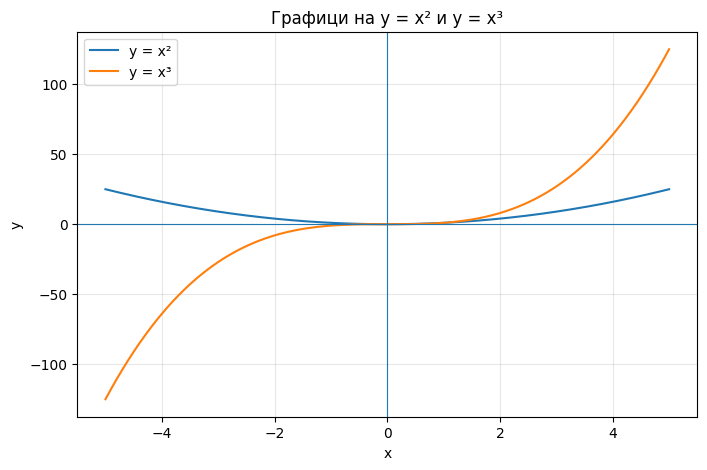

In [22]:
#5
x = np.linspace(-5, 5, 400)
y2 = x ** 2
y3 = x ** 3

plt.figure(figsize=(8, 5))
plt.plot(x, y2, label="y = x²")
plt.plot(x, y3, label="y = x³")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Графици на y = x² и y = x³")
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

Не е пронајдена slika.jpg
Димензии на сликата: (180, 240, 3)


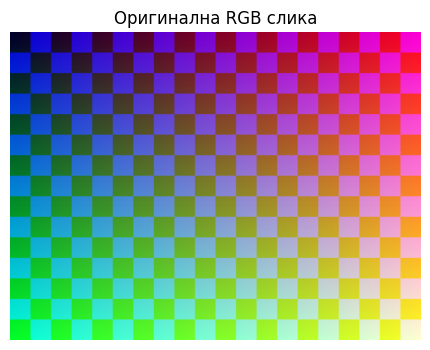

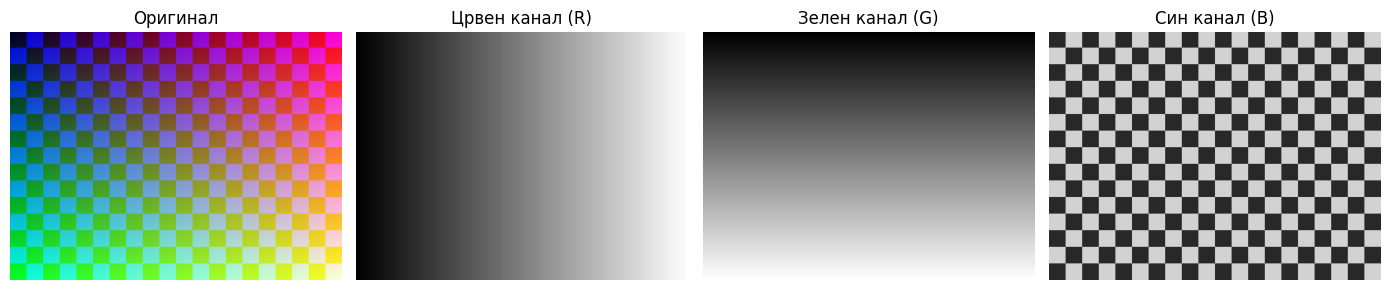

In [23]:
#6
image_path = Path("slika.jpg")

if image_path.exists():
    slika = np.array(Image.open(image_path).convert("RGB"), dtype=np.uint8)
    print(f"Вчитана е сликата: {image_path.resolve()}")
else:
    print("Не е пронајдена slika.jpg")
    h, w = 180, 240
    yy, xx = np.mgrid[0:h, 0:w]
    r = (xx / (w - 1) * 255).astype(np.uint8)
    g = (yy / (h - 1) * 255).astype(np.uint8)
    b = (((xx // 12 + yy // 12) % 2) * 170 + 40).astype(np.uint8)
    slika = np.dstack((r, g, b))

print("Димензии на сликата:", slika.shape)
plt.figure(figsize=(6, 4))
plt.imshow(slika)
plt.title("Оригинална RGB слика")
plt.axis("off")
plt.show()

r = slika[:, :, 0]
g = slika[:, :, 1]
b = slika[:, :, 2]

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
axes[0].imshow(slika)
axes[0].set_title("Оригинал")
axes[1].imshow(r, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Црвен канал (R)")
axes[2].imshow(g, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Зелен канал (G)")
axes[3].imshow(b, cmap="gray", vmin=0, vmax=255)
axes[3].set_title("Син канал (B)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

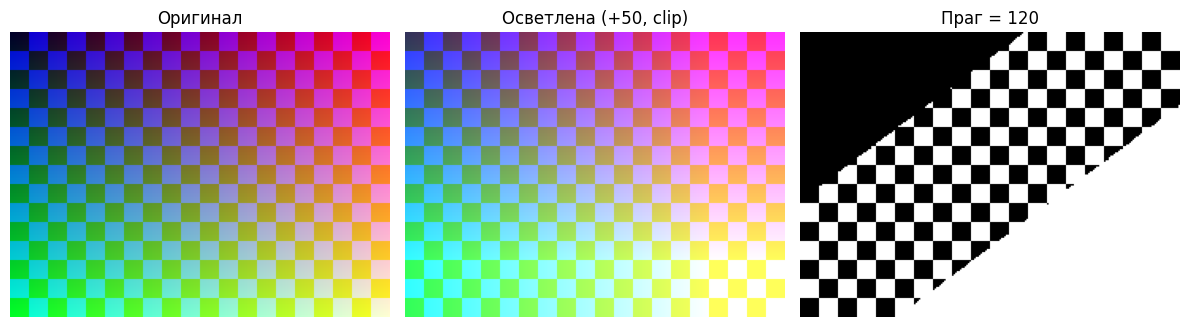

In [24]:
#7
posvetlena = np.clip(slika.astype(np.int16) + 50, 0, 255).astype(np.uint8)
siva_osnovna = np.mean(slika, axis=2).astype(np.uint8)
prag_120 = np.where(siva_osnovna >= 120, 255, 0).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(slika)
axes[0].set_title("Оригинал")
axes[1].imshow(posvetlena)
axes[1].set_title("Осветлена (+50, clip)")
axes[2].imshow(prag_120, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Праг = 120")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

#Проширена

In [14]:
a = np.random.rand(1_000_000).astype(np.float32)

In [15]:
%%timeit -n 3 -r 3
rezultat_ciklus = np.empty_like(a)
for i in range(a.size):
    rezultat_ciklus[i] = a[i] * 2

316 ms ± 6.5 ms per loop (mean ± std. dev. of 3 runs, 3 loops each)


In [10]:
%%timeit -n 3 -r 3
a * 2

804 µs ± 271 µs per loop (mean ± std. dev. of 3 runs, 3 loops each)


In [11]:
def normaliziraj(slika):
    slika_float = np.asarray(slika, dtype=np.float32)
    return slika_float / 255.0

slika_normalizirana = normaliziraj(slika)
print("Тип:", slika_normalizirana.dtype)
print("Минимум:", slika_normalizirana.min())
print("Максимум:", slika_normalizirana.max())
print("Shape:", slika_normalizirana.shape)

Тип: float32
Минимум: 0.0
Максимум: 1.0
Shape: (180, 240, 3)


In [12]:
slika_float = slika.astype(np.float32)
mean = slika_float.mean(axis=(0, 1), keepdims=True)
std = slika_float.std(axis=(0, 1), keepdims=True)
std_bez_nula = np.where(std == 0, 1.0, std)
slika_standardizirana = (slika_float - mean) / std_bez_nula

print("Shape на mean:", mean.shape)
print("Средна вредност по канал (R, G, B):", mean.reshape(-1))
print("Std по канал (R, G, B):", std.reshape(-1))
print("Shape на резултатот:", slika_standardizirana.shape)
print("Тип на резултатот:", slika_standardizirana.dtype)

Shape на mean: (1, 1, 3)
Средна вредност по канал (R, G, B): [127.004166 127.005554 125.      ]
Std по канал (R, G, B): [73.889725 74.02421  85.021255]
Shape на резултатот: (180, 240, 3)
Тип на резултатот: float32


In [13]:
def hwc_to_chw(slika_hwc):
    if slika_hwc.ndim != 3:
        raise ValueError("Очекуваме слика со 3 димензии: (H, W, C).")
    return np.transpose(slika_hwc, (2, 0, 1))


def chw_to_hwc(slika_chw):
    if slika_chw.ndim != 3:
        raise ValueError("Очекуваме низа со 3 димензии: (C, H, W).")
    return np.transpose(slika_chw, (1, 2, 0))

slika_chw = hwc_to_chw(slika)
slika_hwc_vratena = chw_to_hwc(slika_chw)

print("Оригинален HWC shape:", slika.shape)
print("CHW shape:", slika_chw.shape)
print("Вратен HWC shape:", slika_hwc_vratena.shape)
print("Сликата е идентична по враќањето:", np.array_equal(slika, slika_hwc_vratena))

Оригинален HWC shape: (180, 240, 3)
CHW shape: (3, 180, 240)
Вратен HWC shape: (180, 240, 3)
Сликата е идентична по враќањето: True


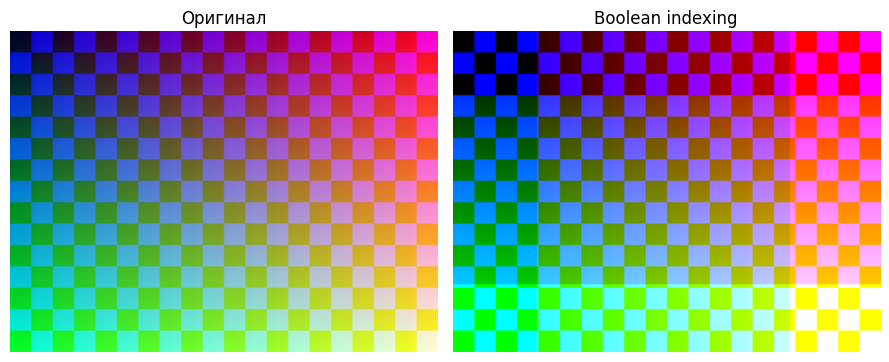

In [14]:
slika_boolean = slika.copy()
slika_boolean[slika_boolean > 200] = 255
slika_boolean[slika_boolean < 50] = 0

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(slika)
axes[0].set_title("Оригинал")
axes[1].imshow(slika_boolean)
axes[1].set_title("Boolean indexing")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

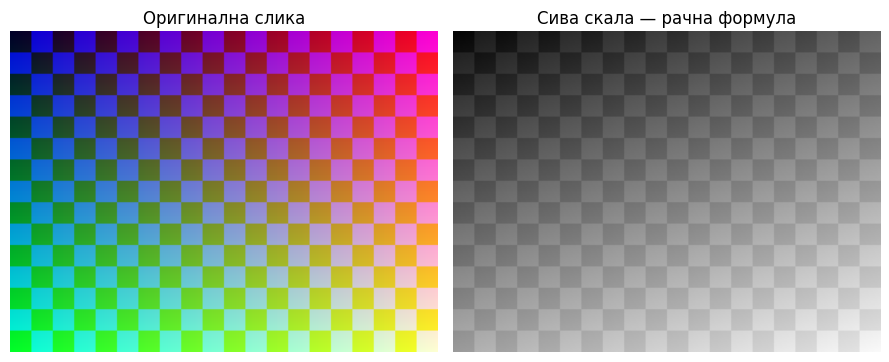

Тип на сивата слика: uint8
Shape на сивата слика: (180, 240)


In [15]:
slika_float = slika.astype(np.float32)
сива_скала = (
    0.299 * slika_float[:, :, 0]
    + 0.587 * slika_float[:, :, 1]
    + 0.114 * slika_float[:, :, 2]
)
сива_скала = np.clip(np.round(сива_скала), 0, 255).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(slika)
axes[0].set_title("Оригинална слика")
axes[1].imshow(сива_скала, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Сива скала — рачна формула")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

print("Тип на сивата слика:", сива_скала.dtype)
print("Shape на сивата слика:", сива_скала.shape)